In [2]:
import numpy as np

a_val = alpha / (k * sx)
d_val = delta / (k * sx)
q_val = delta / alpha

g_val = np.array([a_val, d_val, q_val])

J = np.array([
    [1 / (k * sx), 0, -alpha / (k**2 * sx), -alpha / (k * sx**2)],
    [0, 1 / (k * sx), -delta / (k**2 * sx), -delta / (k * sx**2)],
    [-delta / (alpha**2), 1 / alpha, 0, 0],
])

C_g = J @ C_z @ J.T

u_g = np.sqrt(np.diag(C_g))
u_a, u_d, u_q = u_g

R_g = C_g / np.outer(u_g, u_g)

print("a =", f"({a_val:.3f} +/- {u_a:.3f}) mm")
print("d =", f"({d_val:.3f} +/- {u_d:.3f}) mm")
print("q =", f"{q_val:.3f} +/- {u_q:.3f}")

print("\nC_g:")
print(C_g)

print("\nR_g:")
print(R_g)

rel_uq_sq_jac = (u_q / q_val) ** 2
rel_uq_sq_formula = (
    (u_delta / delta) ** 2
    + (u_alpha / alpha) ** 2
    - 2 * cov_alpha_delta / (alpha * delta)
)

print(f"\nVerifica (u(q)/q)^2 Jacobiano: {rel_uq_sq_jac:.6f}")
print(f"Verifica (u(q)/q)^2 formula:   {rel_uq_sq_formula:.6f}")
print(f"Verifica superata: {np.isclose(rel_uq_sq_jac, rel_uq_sq_formula)}")

a = (0.910 +/- 0.027) mm
d = (5.180 +/- 0.124) mm
q = 5.692 +/- 0.150

C_g:
[[ 0.00073805  0.0018304  -0.00260528]
 [ 0.0018304   0.0154412   0.00551868]
 [-0.00260528  0.00551868  0.02236127]]

R_g:
[[ 1.          0.54220384 -0.64130381]
 [ 0.54220384  1.          0.29699324]
 [-0.64130381  0.29699324  1.        ]]

Verifica (u(q)/q)^2 Jacobiano: 0.000690
Verifica (u(q)/q)^2 formula:   0.000690
Verifica superata: True


C_z:
[[ 0.000324  -0.0005265  0.         0.       ]
 [-0.0005265  0.002025   0.         0.       ]
 [ 0.         0.         0.0001     0.       ]
 [ 0.         0.         0.         0.0004   ]]
Simmetrica: True
Diagonale positiva: True
Autovalori: [0.0001     0.00017422 0.0004     0.00217478]
Autovalori non negativi: True

R_z:
[[ 1.   -0.65  0.    0.  ]
 [-0.65  1.    0.    0.  ]
 [ 0.    0.    1.    0.  ]
 [ 0.    0.    0.    1.  ]]


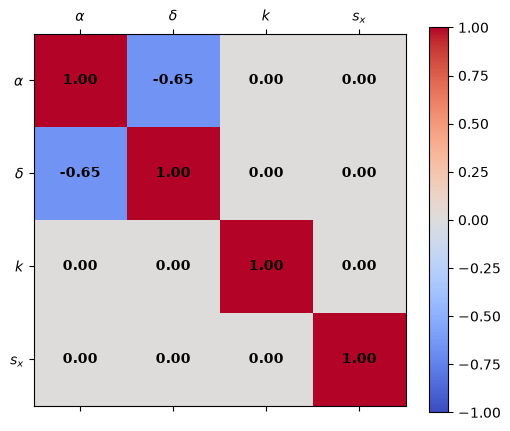

In [1]:
import matplotlib.pyplot as plt
import numpy as np

alpha = 0.910
u_alpha = 0.018

delta = 5.180
u_delta = 0.045

k = 1.000
u_k = 0.010

sx = 1.000
u_sx = 0.020

z = np.array([alpha, delta, k, sx])
rho_alpha_delta = -0.65

C_z = np.zeros((4, 4))
C_z[0, 0] = u_alpha**2
C_z[1, 1] = u_delta**2
C_z[2, 2] = u_k**2
C_z[3, 3] = u_sx**2

cov_alpha_delta = rho_alpha_delta * u_alpha * u_delta
C_z[0, 1] = cov_alpha_delta
C_z[1, 0] = cov_alpha_delta

print("C_z:")
print(C_z)

is_symmetric = np.allclose(C_z, C_z.T)
positive_diag = np.all(np.diag(C_z) > 0)
eigenvalues = np.linalg.eigvalsh(C_z)
non_negative_eig = np.all(eigenvalues >= -1e-14)

print(f"Simmetrica: {is_symmetric}")
print(f"Diagonale positiva: {positive_diag}")
print(f"Autovalori: {eigenvalues}")
print(f"Autovalori non negativi: {non_negative_eig}")

uncertainties = np.sqrt(np.diag(C_z))
R_z = C_z / np.outer(uncertainties, uncertainties)

print("\nR_z:")
print(R_z)

fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.matshow(R_z, vmin=-1, vmax=1, cmap="coolwarm")
fig.colorbar(cax)

labels = [r"$\alpha$", r"$\delta$", r"$k$", r"$s_x$"]
ax.set_xticks(range(4))
ax.set_yticks(range(4))
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)

for i in range(4):
  for j in range(4):
    ax.text(
        j,
        i,
        f"{R_z[i, j]:.2f}",
        ha="center",
        va="center",
        color="black",
        weight="bold",
    )

plt.show()

Grandezza | Nominale | Inc. Lineare | Media MC | Dev. MC | Intervallo [16, 84]
a         | 0.910    | 0.027        | 0.910   | 0.027   | [0.884, 0.937]
d         | 5.180    | 0.124        | 5.183   | 0.125   | [5.059, 5.306]
q         | 5.692    | 0.150        | 5.695   | 0.150   | [5.546, 5.844]


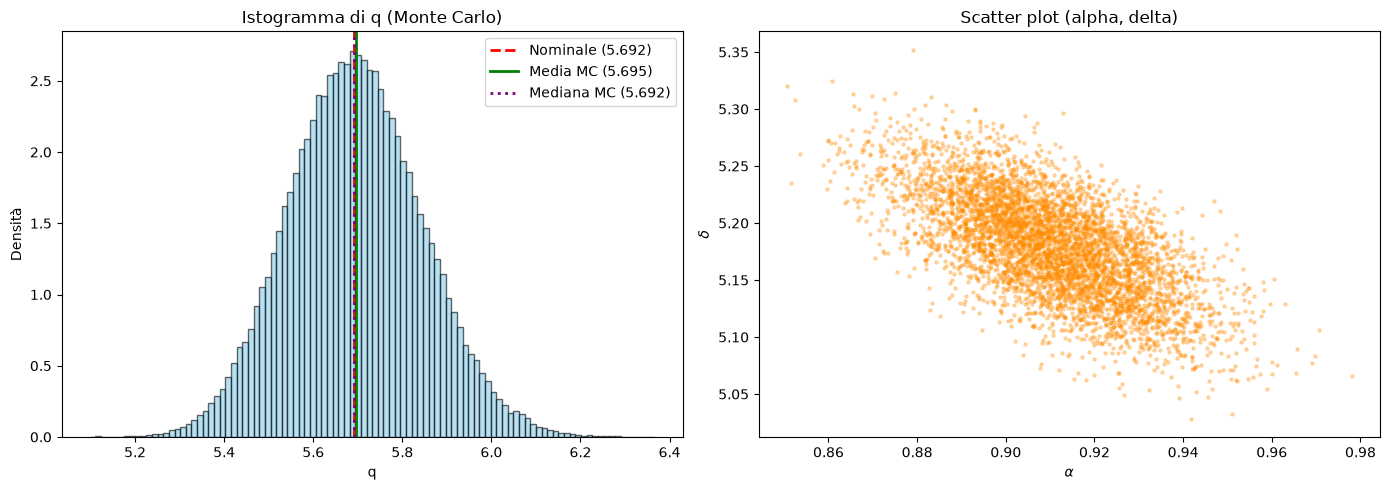

In [3]:
M = 100000
rng = np.random.default_rng(20261003)

media_input = z
campioni = rng.multivariate_normal(mean=media_input, cov=C_z, size=M)

alpha_mc = campioni[:, 0]
delta_mc = campioni[:, 1]
k_mc = campioni[:, 2]
sx_mc = campioni[:, 3]

a_mc = alpha_mc / (k_mc * sx_mc)
d_mc = delta_mc / (k_mc * sx_mc)
q_mc = delta_mc / alpha_mc

a_mean, a_std = np.mean(a_mc), np.std(a_mc, ddof=1)
a_med = np.median(a_mc)
a_p16, a_p84 = np.percentile(a_mc, [16, 84])

d_mean, d_std = np.mean(d_mc), np.std(d_mc, ddof=1)
d_med = np.median(d_mc)
d_p16, d_p84 = np.percentile(d_mc, [16, 84])

q_mean, q_std = np.mean(q_mc), np.std(q_mc, ddof=1)
q_med = np.median(q_mc)
q_p16, q_p84 = np.percentile(q_mc, [16, 84])

print(
    f"Grandezza | Nominale | Inc. Lineare | Media MC | Dev. MC | Intervallo"
    f" [16, 84]"
)
print(
    f"a         | {a_val:.3f}    | {u_a:.3f}        | {a_mean:.3f}   |"
    f" {a_std:.3f}   | [{a_p16:.3f}, {a_p84:.3f}]"
)
print(
    f"d         | {d_val:.3f}    | {u_d:.3f}        | {d_mean:.3f}   |"
    f" {d_std:.3f}   | [{d_p16:.3f}, {d_p84:.3f}]"
)
print(
    f"q         | {q_val:.3f}    | {u_q:.3f}        | {q_mean:.3f}   |"
    f" {q_std:.3f}   | [{q_p16:.3f}, {q_p84:.3f}]"
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.hist(
    q_mc, bins=100, density=True, alpha=0.6, color="skyblue", edgecolor="black"
)
ax1.axvline(
    q_val, color="red", linestyle="--", linewidth=2, label=f"Nominale ({q_val:.3f})"
)
ax1.axvline(
    q_mean,
    color="green",
    linestyle="-",
    linewidth=2,
    label=f"Media MC ({q_mean:.3f})",
)
ax1.axvline(
    q_med,
    color="purple",
    linestyle=":",
    linewidth=2,
    label=f"Mediana MC ({q_med:.3f})",
)
ax1.set_title("Istogramma di q (Monte Carlo)")
ax1.set_xlabel("q")
ax1.set_ylabel("Densità")
ax1.legend()

idx_sample = rng.choice(M, size=5000, replace=False)
ax2.scatter(
    alpha_mc[idx_sample],
    delta_mc[idx_sample],
    alpha=0.3,
    s=5,
    color="darkorange",
)
ax2.set_title("Scatter plot (alpha, delta)")
ax2.set_xlabel(r"$\alpha$")
ax2.set_ylabel(r"$\delta$")

plt.tight_layout()
plt.show()


=== CONFRONTO INCERTEZZE (CORRELATA vs NON CORRELATA) ===
u(a): Correlata = 0.0272, Non correlata = 0.0272 (MC: 0.0271)
u(d): Correlata = 0.1243, Non correlata = 0.1243 (MC: 0.1242)
u(q): Correlata = 0.1495, Non correlata = 0.1230 (MC: 0.1231)


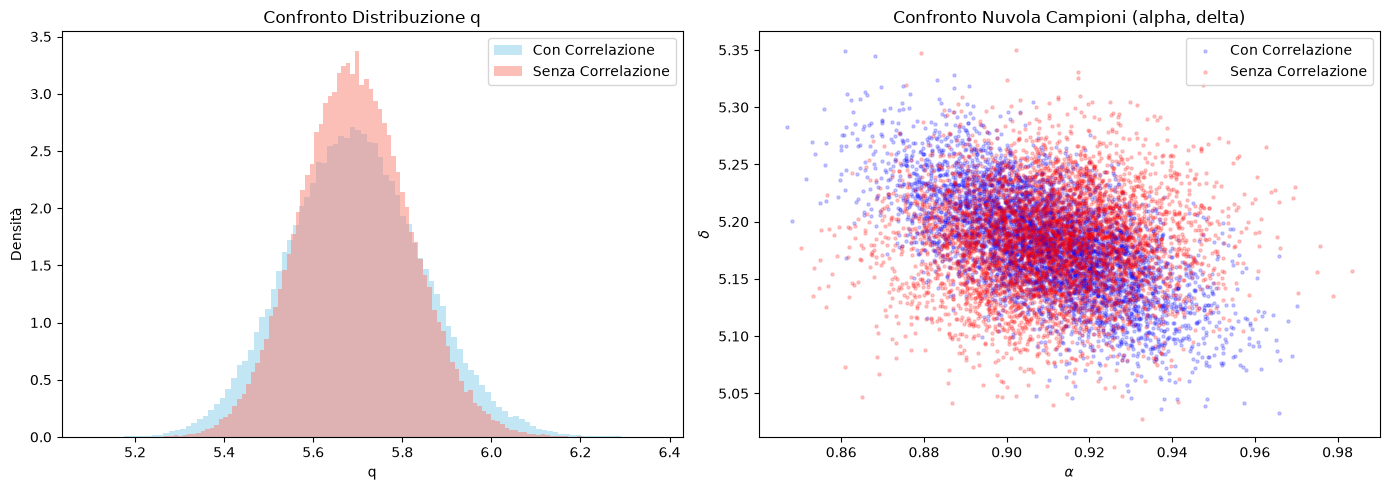

In [5]:
C_z_uncorrated = C_z.copy()
C_z_uncorrated[0, 1] = 0.0
C_z_uncorrated[1, 0] = 0.0

C_g_uncorrated = J @ C_z_uncorrated @ J.T
u_g_uncorrated = np.sqrt(np.diag(C_g_uncorrated))
u_a_uncorr, u_d_uncorr, u_q_uncorr = u_g_uncorrated

campioni_uncorr = rng.multivariate_normal(
    mean=media_input, cov=C_z_uncorrated, size=M
)
alpha_mc_u = campioni_uncorr[:, 0]
delta_mc_u = campioni_uncorr[:, 1]
k_mc_u = campioni_uncorr[:, 2]
sx_mc_u = campioni_uncorr[:, 3]

a_mc_u = alpha_mc_u / (k_mc_u * sx_mc_u)
d_mc_u = delta_mc_u / (k_mc_u * sx_mc_u)
q_mc_u = delta_mc_u / alpha_mc_u

a_std_u = np.std(a_mc_u, ddof=1)
d_std_u = np.std(d_mc_u, ddof=1)
q_std_u = np.std(q_mc_u, ddof=1)

print("=== CONFRONTO INCERTEZZE (CORRELATA vs NON CORRELATA) ===")
print(
    f"u(a): Correlata = {u_a:.4f}, Non correlata = {u_a_uncorr:.4f} (MC:"
    f" {a_std_u:.4f})"
)
print(
    f"u(d): Correlata = {u_d:.4f}, Non correlata = {u_d_uncorr:.4f} (MC:"
    f" {d_std_u:.4f})"
)
print(
    f"u(q): Correlata = {u_q:.4f}, Non correlata = {u_q_uncorr:.4f} (MC:"
    f" {q_std_u:.4f})"
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.hist(
    q_mc,
    bins=100,
    density=True,
    alpha=0.5,
    color="skyblue",
    label="Con Correlazione",
)
ax1.hist(
    q_mc_u,
    bins=100,
    density=True,
    alpha=0.5,
    color="salmon",
    label="Senza Correlazione",
)
ax1.set_title("Confronto Distribuzione q")
ax1.set_xlabel("q")
ax1.set_ylabel("Densità")
ax1.legend()

idx_sample = rng.choice(M, size=5000, replace=False)
ax2.scatter(
    alpha_mc[idx_sample],
    delta_mc[idx_sample],
    alpha=0.2,
    s=5,
    color="blue",
    label="Con Correlazione",
)
ax2.scatter(
    alpha_mc_u[idx_sample],
    delta_mc_u[idx_sample],
    alpha=0.2,
    s=5,
    color="red",
    label="Senza Correlazione",
)
ax2.set_title("Confronto Nuvola Campioni (alpha, delta)")
ax2.set_xlabel(r"$\alpha$")
ax2.set_ylabel(r"$\delta$")
ax2.legend()

plt.tight_layout()
plt.show()

Frazioni percentuali di varianza:
a -> Fit: 43.90%, k: 11.22%, sx: 44.88%
d -> Fit: 13.11%, k: 17.38%, sx: 69.51%
q -> Fit: 100.00%, k: 0.00%, sx: 0.00%


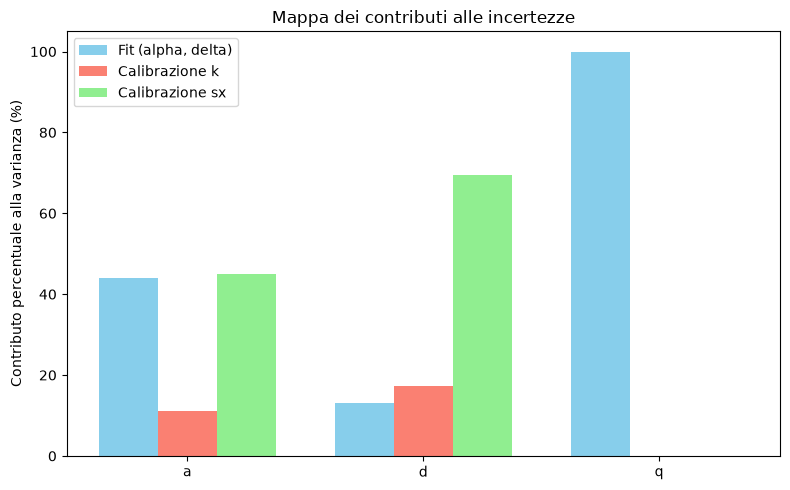

In [6]:
C_z1 = np.zeros_like(C_z)
C_z1[0:2, 0:2] = C_z[0:2, 0:2]

C_z2 = np.zeros_like(C_z)
C_z2[2, 2] = C_z[2, 2]

C_z3 = np.zeros_like(C_z)
C_z3[3, 3] = C_z[3, 3]

C_g1 = J @ C_z1 @ J.T
C_g2 = J @ C_z2 @ J.T
C_g3 = J @ C_z3 @ J.T

var_g1 = np.diag(C_g1)
var_g2 = np.diag(C_g2)
var_g3 = np.diag(C_g3)

total_var = var_g1 + var_g2 + var_g3

frac_1 = var_g1 / total_var * 100
frac_2 = var_g2 / total_var * 100
frac_3 = var_g3 / total_var * 100

print("Frazioni percentuali di varianza:")
print(f"a -> Fit: {frac_1[0]:.2f}%, k: {frac_2[0]:.2f}%, sx: {frac_3[0]:.2f}%")
print(f"d -> Fit: {frac_1[1]:.2f}%, k: {frac_2[1]:.2f}%, sx: {frac_3[1]:.2f}%")
print(f"q -> Fit: {frac_1[2]:.2f}%, k: {frac_2[2]:.2f}%, sx: {frac_3[2]:.2f}%")

labels_g = ["a", "d", "q"]
x = np.arange(len(labels_g))
width = 0.25

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    x - width,
    [frac_1[0], frac_1[1], frac_1[2]],
    width,
    label="Fit (alpha, delta)",
    color="skyblue",
)
ax.bar(
    x,
    [frac_2[0], frac_2[1], frac_2[2]],
    width,
    label="Calibrazione k",
    color="salmon",
)
ax.bar(
    x + width,
    [frac_3[0], frac_3[1], frac_3[2]],
    width,
    label="Calibrazione sx",
    color="lightgreen",
)

ax.set_ylabel("Contributo percentuale alla varianza (%)")
ax.set_title("Mappa dei contributi alle incertezze")
ax.set_xticks(x)
ax.set_xticklabels(labels_g)
ax.legend()

plt.tight_layout()
plt.show()

In [7]:
import numpy as np


def get_uncertainties(C_z_custom):
  C_g_custom = J @ C_z_custom @ J.T
  return np.sqrt(np.diag(C_g_custom))


u_nom = np.array([u_a, u_d, u_q])

C_z_sc2 = C_z.copy()
C_z_sc2[0, 1] = 0.0
C_z_sc2[1, 0] = 0.0
u_sc2 = get_uncertainties(C_z_sc2)

C_z_sc3 = C_z.copy()
C_z_sc3[2, 2] = (u_k / 2) ** 2
u_sc3 = get_uncertainties(C_z_sc3)

C_z_sc4 = C_z.copy()
C_z_sc4[3, 3] = (u_sx / 2) ** 2
u_sc4 = get_uncertainties(C_z_sc4)

C_z_sc5 = C_z.copy()
C_z_sc5[0:2, 0:2] = C_z[0:2, 0:2] / 4.0
u_sc5 = get_uncertainties(C_z_sc5)

scenarios = [
    ("Nominale", u_nom),
    ("Correlazione ignorata", u_sc2),
    ("Calibrazione k dimezzata", u_sc3),
    ("Calibrazione sx dimezzata", u_sc4),
    ("Statistica fit migliorata", u_sc5),
]

print(f"{'Scenario':<28} | {'u(a)':<10} | {'u(d)':<10} | {'u(q)':<10}")
print("-" * 65)
for name, u_vals in scenarios:
  print(
      f"{name:<28} | {u_vals[0]:.4f}     | {u_vals[1]:.4f}     |"
      f" {u_vals[2]:.4f}"
  )

Scenario                     | u(a)       | u(d)       | u(q)      
-----------------------------------------------------------------
Nominale                     | 0.0272     | 0.1243     | 0.1495
Correlazione ignorata        | 0.0272     | 0.1243     | 0.1230
Calibrazione k dimezzata     | 0.0260     | 0.1159     | 0.1495
Calibrazione sx dimezzata    | 0.0221     | 0.0860     | 0.1495
Statistica fit migliorata    | 0.0222     | 0.1180     | 0.0748
